In [ ]:
# Block 1
%load_ext autoreload
%autoreload 1

# Watch the modules these cells call into
%aimport utility
%aimport config
import pandas as pd
import numpy as np
from IPython.display import display
import os
import re
import pydicom
import glob
from pathlib import Path
from sklearn.model_selection import (
    StratifiedShuffleSplit,
    StratifiedKFold,
)
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from tqdm.auto import tqdm
import hashlib
import inspect
import json

import config
import utility

In [ ]:
# Block 2
# Read the four case-description CSVs
csv_df_list = [pd.read_csv(csv) for csv in config.CSV_FILES]

In [ ]:
# Block 3
# Resolve every CSV path to a DICOM file on disk
def fix_if_missing(path):
    """Repair a path whose filename is missing from the CSV."""
    original = config.ORIGINAL_DATASET_ROOT.joinpath(*path.split("/")[:3])

    if original.exists():
        return str(original)
    parts = path.split("/")
    m = re.search(r"(P_.*)", parts[0])

    if m:
        parts[0] = m.group(1) + ".dcm"
        fixed = config.ORIGINAL_DATASET_ROOT.joinpath(*parts[:3])
        if fixed.exists():
            return str(fixed)
    return ""


found_all = True
for i, df in enumerate(csv_df_list):
    df["full_path"] = df["image file path"].apply(fix_if_missing)
    df["crop_path"] = df["cropped image file path"].apply(fix_if_missing)
    df["mask_path"] = df["ROI mask file path"].apply(fix_if_missing)

    # Report rows whose paths could not be resolved
    missing_rows = df[df[["full_path", "crop_path", "mask_path"]].eq("").any(axis=1)]

    print(f"--- DataFrame {i} : Found {len(missing_rows)} rows with missing files ---")
    if not missing_rows.empty:
        display(missing_rows.head(20))
        found_all = False


if found_all:
    print("None of the dataframe have missing image folder path, showing head of each dataframe")
    for df in csv_df_list:
        display(df.head())

--- DataFrame 0 : Found 0 rows with missing files ---
--- DataFrame 1 : Found 0 rows with missing files ---
--- DataFrame 2 : Found 0 rows with missing files ---
--- DataFrame 3 : Found 0 rows with missing files ---
None of the dataframe have missing image folder path, showing head of each dataframe


,patient_id,breast density,left or right breast,image view,abnormality id,abnormality type,calc type,calc distribution,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path,full_path,crop_path,mask_path
0,P_00038,2,LEFT,CC,1,calcification,PUNCTATE-PLEOMORPHIC,CLUSTERED,4,BENIGN,2,Calc-Test_P_00038_LEFT_CC/1.3.6.1.4.1.9590.100...,Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.1...,Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.1...,C:\Users\User\Downloads\cbis_ddsm\P_00038_LEFT...,C:\Users\User\Downloads\cbis_ddsm\Calc-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Calc-Test_P_...
1,P_00038,2,LEFT,MLO,1,calcification,PUNCTATE-PLEOMORPHIC,CLUSTERED,4,BENIGN,2,Calc-Test_P_00038_LEFT_MLO/1.3.6.1.4.1.9590.10...,Calc-Test_P_00038_LEFT_MLO_1/1.3.6.1.4.1.9590....,Calc-Test_P_00038_LEFT_MLO_1/1.3.6.1.4.1.9590....,C:\Users\User\Downloads\cbis_ddsm\P_00038_LEFT...,C:\Users\User\Downloads\cbis_ddsm\P_00038_LEFT...,C:\Users\User\Downloads\cbis_ddsm\P_00038_LEFT...
2,P_00038,2,RIGHT,CC,1,calcification,VASCULAR,NaN,2,BENIGN_WITHOUT_CALLBACK,5,Calc-Test_P_00038_RIGHT_CC/1.3.6.1.4.1.9590.10...,Calc-Test_P_00038_RIGHT_CC_1/1.3.6.1.4.1.9590....,Calc-Test_P_00038_RIGHT_CC_1/1.3.6.1.4.1.9590....,C:\Users\User\Downloads\cbis_ddsm\P_00038_RIGH...,C:\Users\User\Downloads\cbis_ddsm\Calc-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Calc-Test_P_...
3,P_00038,2,RIGHT,CC,2,calcification,VASCULAR,NaN,2,BENIGN_WITHOUT_CALLBACK,5,Calc-Test_P_00038_RIGHT_CC/1.3.6.1.4.1.9590.10...,Calc-Test_P_00038_RIGHT_CC_2/1.3.6.1.4.1.9590....,Calc-Test_P_00038_RIGHT_CC_2/1.3.6.1.4.1.9590....,C:\Users\User\Downloads\cbis_ddsm\P_00038_RIGH...,C:\Users\User\Downloads\cbis_ddsm\Calc-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Calc-Test_P_...
4,P_00038,2,RIGHT,MLO,1,calcification,VASCULAR,NaN,2,BENIGN_WITHOUT_CALLBACK,5,Calc-Test_P_00038_RIGHT_MLO/1.3.6.1.4.1.9590.1...,Calc-Test_P_00038_RIGHT_MLO_1/1.3.6.1.4.1.9590...,Calc-Test_P_00038_RIGHT_MLO_1/1.3.6.1.4.1.9590...,C:\Users\User\Downloads\cbis_ddsm\P_00038_RIGH...,C:\Users\User\Downloads\cbis_ddsm\P_00038_RIGH...,C:\Users\User\Downloads\cbis_ddsm\P_00038_RIGH...


,patient_id,breast density,left or right breast,image view,abnormality id,abnormality type,calc type,calc distribution,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path,full_path,crop_path,mask_path
0,P_00005,3,RIGHT,CC,1,calcification,AMORPHOUS,CLUSTERED,3,MALIGNANT,3,Calc-Training_P_00005_RIGHT_CC/1.3.6.1.4.1.959...,Calc-Training_P_00005_RIGHT_CC_1/1.3.6.1.4.1.9...,Calc-Training_P_00005_RIGHT_CC_1/1.3.6.1.4.1.9...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...
1,P_00005,3,RIGHT,MLO,1,calcification,AMORPHOUS,CLUSTERED,3,MALIGNANT,3,Calc-Training_P_00005_RIGHT_MLO/1.3.6.1.4.1.95...,Calc-Training_P_00005_RIGHT_MLO_1/1.3.6.1.4.1....,Calc-Training_P_00005_RIGHT_MLO_1/1.3.6.1.4.1....,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...
2,P_00007,4,LEFT,CC,1,calcification,PLEOMORPHIC,LINEAR,4,BENIGN,4,Calc-Training_P_00007_LEFT_CC/1.3.6.1.4.1.9590...,Calc-Training_P_00007_LEFT_CC_1/1.3.6.1.4.1.95...,Calc-Training_P_00007_LEFT_CC_1/1.3.6.1.4.1.95...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...
3,P_00007,4,LEFT,MLO,1,calcification,PLEOMORPHIC,LINEAR,4,BENIGN,4,Calc-Training_P_00007_LEFT_MLO/1.3.6.1.4.1.959...,Calc-Training_P_00007_LEFT_MLO_1/1.3.6.1.4.1.9...,Calc-Training_P_00007_LEFT_MLO_1/1.3.6.1.4.1.9...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...
4,P_00008,1,LEFT,CC,1,calcification,NaN,REGIONAL,2,BENIGN_WITHOUT_CALLBACK,3,Calc-Training_P_00008_LEFT_CC/1.3.6.1.4.1.9590...,Calc-Training_P_00008_LEFT_CC_1/1.3.6.1.4.1.95...,Calc-Training_P_00008_LEFT_CC_1/1.3.6.1.4.1.95...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...


,patient_id,breast_density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path,full_path,crop_path,mask_path
0,P_00016,4,LEFT,CC,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,5,Mass-Test_P_00016_LEFT_CC/1.3.6.1.4.1.9590.100...,Mass-Test_P_00016_LEFT_CC_1/1.3.6.1.4.1.9590.1...,Mass-Test_P_00016_LEFT_CC_1/1.3.6.1.4.1.9590.1...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...
1,P_00016,4,LEFT,MLO,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,5,Mass-Test_P_00016_LEFT_MLO/1.3.6.1.4.1.9590.10...,Mass-Test_P_00016_LEFT_MLO_1/1.3.6.1.4.1.9590....,Mass-Test_P_00016_LEFT_MLO_1/1.3.6.1.4.1.9590....,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...
2,P_00017,2,LEFT,CC,1,mass,ROUND,CIRCUMSCRIBED,4,MALIGNANT,4,Mass-Test_P_00017_LEFT_CC/1.3.6.1.4.1.9590.100...,Mass-Test_P_00017_LEFT_CC_1/1.3.6.1.4.1.9590.1...,Mass-Test_P_00017_LEFT_CC_1/1.3.6.1.4.1.9590.1...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...
3,P_00017,2,LEFT,MLO,1,mass,ROUND,ILL_DEFINED,4,MALIGNANT,4,Mass-Test_P_00017_LEFT_MLO/1.3.6.1.4.1.9590.10...,Mass-Test_P_00017_LEFT_MLO_1/1.3.6.1.4.1.9590....,Mass-Test_P_00017_LEFT_MLO_1/1.3.6.1.4.1.9590....,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...
4,P_00032,3,RIGHT,CC,1,mass,ROUND,OBSCURED,0,BENIGN,2,Mass-Test_P_00032_RIGHT_CC/1.3.6.1.4.1.9590.10...,Mass-Test_P_00032_RIGHT_CC_1/1.3.6.1.4.1.9590....,Mass-Test_P_00032_RIGHT_CC_1/1.3.6.1.4.1.9590....,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...


,patient_id,breast_density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path,full_path,crop_path,mask_path
0,P_00001,3,LEFT,CC,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...
1,P_00001,3,LEFT,MLO,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...
2,P_00004,3,LEFT,CC,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...
3,P_00004,3,LEFT,MLO,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...
4,P_00004,3,RIGHT,MLO,1,mass,OVAL,CIRCUMSCRIBED,4,BENIGN,5,Mass-Training_P_00004_RIGHT_MLO/1.3.6.1.4.1.95...,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...


In [4]:
# Block 4
# Check whether the full, crop and mask paths ever coincide
for i, df in enumerate(csv_df_list):
    full_eq_crop = (df["full_path"] == df["crop_path"]).sum()
    full_eq_mask = (df["full_path"] == df["mask_path"]).sum()
    crop_eq_mask = (df["crop_path"] == df["mask_path"]).sum()

    # Print the results for the current DataFrame
    print(f"DataFrame {i}:")
    print(f"  Rows where full_path == crop_path: {full_eq_crop}")
    print(f"  Rows where full_path == mask_path: {full_eq_mask}")
    print(f"  Rows where crop_path == mask_path: {crop_eq_mask}")
    print("-" * 40)

DataFrame 0:
  Rows where full_path == crop_path: 0
  Rows where full_path == mask_path: 0
  Rows where crop_path == mask_path: 326
----------------------------------------
DataFrame 1:
  Rows where full_path == crop_path: 0
  Rows where full_path == mask_path: 0
  Rows where crop_path == mask_path: 1545
----------------------------------------
DataFrame 2:
  Rows where full_path == crop_path: 0
  Rows where full_path == mask_path: 0
  Rows where crop_path == mask_path: 367
----------------------------------------
DataFrame 3:
  Rows where full_path == crop_path: 0
  Rows where full_path == mask_path: 0
  Rows where crop_path == mask_path: 1226
----------------------------------------


In [5]:
# Block 5
# Resolve the DICOM files behind every stored path
def get_dcm_files(folder):
    """Return all .dcm files directly inside a folder."""
    return sorted(Path(folder).glob("*.dcm"))


for df in csv_df_list:
    full_images = []
    crop_images = []
    mask_images = []

    for _, row in df.iterrows():
        # ---------- Full image ----------
        full_files = get_dcm_files(row["full_path"])

        if len(full_files) != 1:
            raise ValueError(f"{row['full_path']} contains {len(full_files)} .dcm files " f"(expected exactly 1)")

        full_images.append(str(full_files[0]))

        # ---------- Crop / Mask ----------
        if row["crop_path"] == row["mask_path"]:
            files = get_dcm_files(row["crop_path"])

            if len(files) != 2:
                raise ValueError(f"{row['crop_path']} contains {len(files)} .dcm files " f"(expected exactly 2)")

            # Smaller file = crop, larger = mask
            files.sort(key=lambda f: f.stat().st_size)

            crop_images.append(str(files[0]))
            mask_images.append(str(files[1]))

        else:
            crop_files = get_dcm_files(row["crop_path"])
            if len(crop_files) != 1:
                raise ValueError(f"{row['crop_path']} contains {len(crop_files)} .dcm files " f"(expected exactly 1)")

            mask_files = get_dcm_files(row["mask_path"])
            if len(mask_files) != 1:
                raise ValueError(f"{row['mask_path']} contains {len(mask_files)} .dcm files " f"(expected exactly 1)")

            crop_images.append(str(crop_files[0]))
            mask_images.append(str(mask_files[0]))

    df["full_image"] = full_images
    df["crop_image"] = crop_images
    df["mask_image"] = mask_images

In [6]:
# Block 6
# Drop the raw path columns and rename the density column
drop_columns = [
    "image file path",
    "cropped image file path",
    "ROI mask file path",
    "full_path",
    "crop_path",
    "mask_path",
]
csv_df_list = [df.drop(columns=drop_columns) for df in csv_df_list]

csv_df_list = [df.rename(columns={"breast_density": "breast density"}) for df in csv_df_list]

for df in csv_df_list:
    display(df.head())

,patient_id,breast density,left or right breast,image view,abnormality id,abnormality type,calc type,calc distribution,assessment,pathology,subtlety,full_image,crop_image,mask_image
0,P_00038,2,LEFT,CC,1,calcification,PUNCTATE-PLEOMORPHIC,CLUSTERED,4,BENIGN,2,C:\Users\User\Downloads\cbis_ddsm\P_00038_LEFT...,C:\Users\User\Downloads\cbis_ddsm\Calc-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Calc-Test_P_...
1,P_00038,2,LEFT,MLO,1,calcification,PUNCTATE-PLEOMORPHIC,CLUSTERED,4,BENIGN,2,C:\Users\User\Downloads\cbis_ddsm\P_00038_LEFT...,C:\Users\User\Downloads\cbis_ddsm\P_00038_LEFT...,C:\Users\User\Downloads\cbis_ddsm\P_00038_LEFT...
2,P_00038,2,RIGHT,CC,1,calcification,VASCULAR,NaN,2,BENIGN_WITHOUT_CALLBACK,5,C:\Users\User\Downloads\cbis_ddsm\P_00038_RIGH...,C:\Users\User\Downloads\cbis_ddsm\Calc-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Calc-Test_P_...
3,P_00038,2,RIGHT,CC,2,calcification,VASCULAR,NaN,2,BENIGN_WITHOUT_CALLBACK,5,C:\Users\User\Downloads\cbis_ddsm\P_00038_RIGH...,C:\Users\User\Downloads\cbis_ddsm\Calc-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Calc-Test_P_...
4,P_00038,2,RIGHT,MLO,1,calcification,VASCULAR,NaN,2,BENIGN_WITHOUT_CALLBACK,5,C:\Users\User\Downloads\cbis_ddsm\P_00038_RIGH...,C:\Users\User\Downloads\cbis_ddsm\P_00038_RIGH...,C:\Users\User\Downloads\cbis_ddsm\P_00038_RIGH...


,patient_id,breast density,left or right breast,image view,abnormality id,abnormality type,calc type,calc distribution,assessment,pathology,subtlety,full_image,crop_image,mask_image
0,P_00005,3,RIGHT,CC,1,calcification,AMORPHOUS,CLUSTERED,3,MALIGNANT,3,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...
1,P_00005,3,RIGHT,MLO,1,calcification,AMORPHOUS,CLUSTERED,3,MALIGNANT,3,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...
2,P_00007,4,LEFT,CC,1,calcification,PLEOMORPHIC,LINEAR,4,BENIGN,4,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...
3,P_00007,4,LEFT,MLO,1,calcification,PLEOMORPHIC,LINEAR,4,BENIGN,4,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...
4,P_00008,1,LEFT,CC,1,calcification,NaN,REGIONAL,2,BENIGN_WITHOUT_CALLBACK,3,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...


,patient_id,breast density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,subtlety,full_image,crop_image,mask_image
0,P_00016,4,LEFT,CC,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,5,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...
1,P_00016,4,LEFT,MLO,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,5,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...
2,P_00017,2,LEFT,CC,1,mass,ROUND,CIRCUMSCRIBED,4,MALIGNANT,4,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...
3,P_00017,2,LEFT,MLO,1,mass,ROUND,ILL_DEFINED,4,MALIGNANT,4,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...
4,P_00032,3,RIGHT,CC,1,mass,ROUND,OBSCURED,0,BENIGN,2,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...,C:\Users\User\Downloads\cbis_ddsm\Mass-Test_P_...


,patient_id,breast density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,subtlety,full_image,crop_image,mask_image
0,P_00001,3,LEFT,CC,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...
1,P_00001,3,LEFT,MLO,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...
2,P_00004,3,LEFT,CC,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...
3,P_00004,3,LEFT,MLO,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...
4,P_00004,3,RIGHT,MLO,1,mass,OVAL,CIRCUMSCRIBED,4,BENIGN,5,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Mass-Trainin...


In [ ]:
# Block 7
# Concatenate the calc and mass CSVs
calc_df = pd.concat([csv_df_list[0], csv_df_list[1]], ignore_index=True)
mass_df = pd.concat([csv_df_list[2], csv_df_list[3]], ignore_index=True)


def create_patient_split(df):
    """Split trainval/test per patient, then assign the folds."""
    patient_df = (
        df.groupby("patient_id")
        .agg(
            has_malignant=("pathology", lambda s: (s == "MALIGNANT").any()),
            has_benign=("pathology", lambda s: s.isin(["BENIGN", "BENIGN_WITHOUT_CALLBACK"]).any()),
        )
        .reset_index()
    )

    patient_df["stratum"] = (
        patient_df["has_malignant"].astype(int).astype(str) + "_" + patient_df["has_benign"].astype(int).astype(str)
    )

    sss = StratifiedShuffleSplit(n_splits=1, test_size=config.TEST_SIZE, random_state=config.RANDOM_STATE)

    train_idx, test_idx = next(sss.split(patient_df["patient_id"], patient_df["stratum"]))

    patient_df["split"] = "trainval"
    patient_df.loc[test_idx, "split"] = "test"

    patient_df["fold"] = -1

    trainval = patient_df.loc[patient_df["split"] == "trainval"].copy()

    skf = StratifiedKFold(n_splits=config.N_FOLDS, shuffle=True, random_state=config.RANDOM_STATE)

    for fold, (_, val_idx) in enumerate(skf.split(trainval["patient_id"], trainval["stratum"])):
        trainval.iloc[val_idx, trainval.columns.get_loc("fold")] = fold

    patient_df.loc[patient_df["split"] == "trainval", "fold"] = trainval["fold"].values

    df = df.merge(patient_df[["patient_id", "split", "fold"]], on="patient_id", how="left")

    return df

In [8]:
# Block 8
# Apply the split to both datasets and rename the image columns
calc_df = create_patient_split(calc_df)
mass_df = create_patient_split(mass_df)

rename_col = {"full_image": "full_dcm", "crop_image": "crop_dcm", "mask_image": "mask_dcm"}
calc_df = calc_df.rename(columns=rename_col)
mass_df = mass_df.rename(columns=rename_col)

datasets = {"calc": calc_df, "mass": mass_df}

In [ ]:
# Block 9
# Signature over the preprocessing code and settings, so a change rebuilds the cache
config.DATASET_ROOT.mkdir(exist_ok=True)

cache_file = config.DATASET_ROOT / "cache.json"

signature_data = {
    "MAX_IMAGE_SIDE": config.MAX_IMAGE_SIDE,
    "MASK_ALIGN_TOLERANCE": config.MASK_ALIGN_TOLERANCE,
    "extract_breast": inspect.getsource(utility.extract_breast),
    "read_dcm": inspect.getsource(utility.read_dcm),
    "resize_image": inspect.getsource(utility.resize_image),
    "align_mask_to_image": inspect.getsource(utility.align_mask_to_image),
}

CURRENT_SIGNATURE = hashlib.sha256(json.dumps(signature_data, sort_keys=True).encode("utf-8")).hexdigest()

In [ ]:
# Block 10
# Build the processed dataset; finished rows are reused while the cache signature matches
cache = {}

if cache_file.exists():
    with open(cache_file, "r") as f:
        cache = json.load(f)

cached_signature = cache.get("signature")
rebuild = cached_signature != CURRENT_SIGNATURE

if rebuild:
    print("Cache invalid -> rebuilding processed dataset")
    excluded_rows = []
    shape_mismatches = []
    excluded_keys = set()
else:
    print("Cache valid -> reusing processed dataset")
    excluded_rows = cache.get("excluded_rows", [])
    shape_mismatches = cache.get("shape_mismatches", [])
    excluded_keys = {(row["full_dcm"], row["mask_dcm"]) for row in excluded_rows}

for dataset_name, df in datasets.items():
    processed_rows = []
    unique_images = df[["full_dcm", "crop_dcm", "mask_dcm"]].drop_duplicates()

    for _, row in tqdm(unique_images.iterrows(), total=len(unique_images), desc=dataset_name):
        if (row["full_dcm"], row["mask_dcm"]) in excluded_keys:
            continue

        matching_rows = df[
            (df["full_dcm"] == row["full_dcm"])
            & (df["crop_dcm"] == row["crop_dcm"])
            & (df["mask_dcm"] == row["mask_dcm"])
        ]
        first = matching_rows.iloc[0]

        view = f'{first["left or right breast"]}_{first["image view"]}'
        abnormality = f'Abnormality_{first["abnormality type"].lower()}_{first["abnormality id"]}'
        view_folder = config.DATASET_ROOT / dataset_name / first["split"] / first["patient_id"] / view
        abnormality_folder = view_folder / abnormality

        full_file = view_folder / "full_image.npy"
        breast_file = view_folder / "breast_mask.npy"
        crop_file = abnormality_folder / "crop_image.npy"
        mask_file = abnormality_folder / "mask_image.npy"

        all_exist = full_file.exists() and breast_file.exists() and crop_file.exists() and mask_file.exists()

        if rebuild or not all_exist:
            full_dcm_arr = utility.read_dcm(row["full_dcm"])
            mask_dcm_arr = utility.read_dcm(row["mask_dcm"])

            if full_dcm_arr.shape != mask_dcm_arr.shape:
                shape_mismatches.append(
                    {
                        "dataset": dataset_name,
                        "full_dcm": row["full_dcm"],
                        "mask_dcm": row["mask_dcm"],
                        "full_shape": full_dcm_arr.shape,
                        "mask_shape": mask_dcm_arr.shape,
                    }
                )
                try:
                    mask_dcm_arr = utility.align_mask_to_image(
                        mask_dcm_arr, full_dcm_arr.shape, tolerance=config.MASK_ALIGN_TOLERANCE
                    )
                except ValueError as e:
                    excluded_rows.append(
                        {
                            "dataset": dataset_name,
                            "patient_id": first["patient_id"],
                            "full_dcm": row["full_dcm"],
                            "mask_dcm": row["mask_dcm"],
                            "reason": str(e),
                        }
                    )
                    excluded_keys.add((row["full_dcm"], row["mask_dcm"]))
                    continue

            view_folder.mkdir(parents=True, exist_ok=True)
            abnormality_folder.mkdir(exist_ok=True)

            full = utility.resize_image(full_dcm_arr, config.MAX_IMAGE_SIDE)
            crop = utility.resize_image(utility.read_dcm(row["crop_dcm"]), config.MAX_IMAGE_SIDE)
            mask = utility.resize_image(mask_dcm_arr, config.MAX_IMAGE_SIDE, is_mask=True)

            breast_mask, bbox = utility.extract_breast(full)

            np.save(full_file, full)
            np.save(breast_file, breast_mask)
            np.save(crop_file, crop)
            np.save(mask_file, mask)
        else:
            bbox = utility.mask_bbox(np.load(breast_file))

        xmin, ymin, xmax, ymax = bbox
        processed_rows.append(
            {
                "full_dcm": row["full_dcm"],
                "crop_dcm": row["crop_dcm"],
                "mask_dcm": row["mask_dcm"],
                "full_image": str(full_file),
                "crop_image": str(crop_file),
                "mask_image": str(mask_file),
                "breast_mask": str(breast_file),
                "breast_xmin": xmin,
                "breast_ymin": ymin,
                "breast_xmax": xmax,
                "breast_ymax": ymax,
            }
        )

    processed_df = pd.DataFrame(processed_rows)
    datasets[dataset_name] = df.merge(processed_df, on=["full_dcm", "crop_dcm", "mask_dcm"], how="left")
    datasets[dataset_name] = datasets[dataset_name].dropna(subset=["full_image", "crop_image", "mask_image"])

if excluded_rows:
    display(pd.DataFrame(excluded_rows))

Cache invalid -> rebuilding processed dataset


calc:   0%|          | 0/1872 [00:00<?, ?it/s]

mass:   0%|          | 0/1696 [00:00<?, ?it/s]

,dataset,patient_id,full_dcm,mask_dcm,reason
0,calc,P_00474,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,C:\Users\User\Downloads\cbis_ddsm\Calc-Trainin...,"Mask shape (1129, 1065) differs from image sha..."


In [ ]:
# Block 11
# Write the metadata and the cache
calc_metadata = config.PROJECT_ROOT / "calc_metadata.csv"
mass_metadata = config.PROJECT_ROOT / "mass_metadata.csv"

datasets["calc"].to_csv(calc_metadata, index=False)
datasets["mass"].to_csv(mass_metadata, index=False)

print(f"Saved -> {calc_metadata}")
print(f"Saved -> {mass_metadata}")

with open(cache_file, "w") as f:
    json.dump(
        {"signature": CURRENT_SIGNATURE, "excluded_rows": excluded_rows, "shape_mismatches": shape_mismatches},
        f,
        indent=2,
    )

print(f"Full/mask shape mismatches (aligned): {len(shape_mismatches)}")
print(f"Rows excluded (mismatch beyond {config.MASK_ALIGN_TOLERANCE:.0%} tolerance): {len(excluded_rows)}")

Saved -> C:\Users\User\Desktop\sch work\fyp\calc_metadata.csv
Saved -> C:\Users\User\Desktop\sch work\fyp\mass_metadata.csv
Full/mask shape mismatches (aligned): 81
Rows excluded (mismatch beyond 15% tolerance): 1


In [ ]:
# Block 12
# Reload the metadata written above
calc_metadata = pd.read_csv(config.PROJECT_ROOT / "calc_metadata.csv")
mass_metadata = pd.read_csv(config.PROJECT_ROOT / "mass_metadata.csv")

In [ ]:
# Block 13
# Lesion size statistics per dataset
stats = {}

for name, metadata in {"calc": calc_metadata, "mass": mass_metadata}.items():
    records = []

    for mask_path in tqdm(metadata["mask_image"], desc=name):
        mask = np.load(mask_path)
        xmin, ymin, xmax, ymax = utility.mask_bbox(mask)
        w = xmax - xmin + 1
        h = ymax - ymin + 1

        records.append({"width": w, "height": h, "side": max(w, h), "area": w * h})

    stats[name] = pd.DataFrame(records)

calc:   0%|          | 0/1871 [00:00<?, ?it/s]

mass:   0%|          | 0/1696 [00:00<?, ?it/s]

In [14]:
# Block 14
# Print the size distribution per dataset
for name, stat in stats.items():
    print("=" * 80)
    print(name.upper())
    print("=" * 80)

    print(stat.describe(percentiles=[0.05, 0.8, 0.85, 0.9, 0.95]))

CALC
             width       height         side           area
count  1871.000000  1871.000000  1871.000000    1871.000000
mean     85.505612    83.952966    97.113843   12989.722074
std      81.692340    88.420071    98.718567   27709.531246
min       6.000000     6.000000     8.000000      48.000000
5%       14.000000    15.000000    17.000000     224.000000
80%     129.000000   122.000000   142.000000   15215.000000
85%     157.000000   144.500000   172.500000   22148.000000
90%     189.000000   185.000000   216.000000   33807.000000
95%     262.000000   249.000000   319.000000   62693.000000
max     517.000000   709.000000   709.000000  308574.000000
MASS
             width       height         side          area
count  1696.000000  1696.000000  1696.000000   1696.000000
mean     64.666274    64.255307    69.145637   4846.702830
std      27.861807    28.328524    29.664784   4804.621379
min      12.000000    15.000000    15.000000    225.000000
5%       31.750000    31.000000    

CALC
trainval


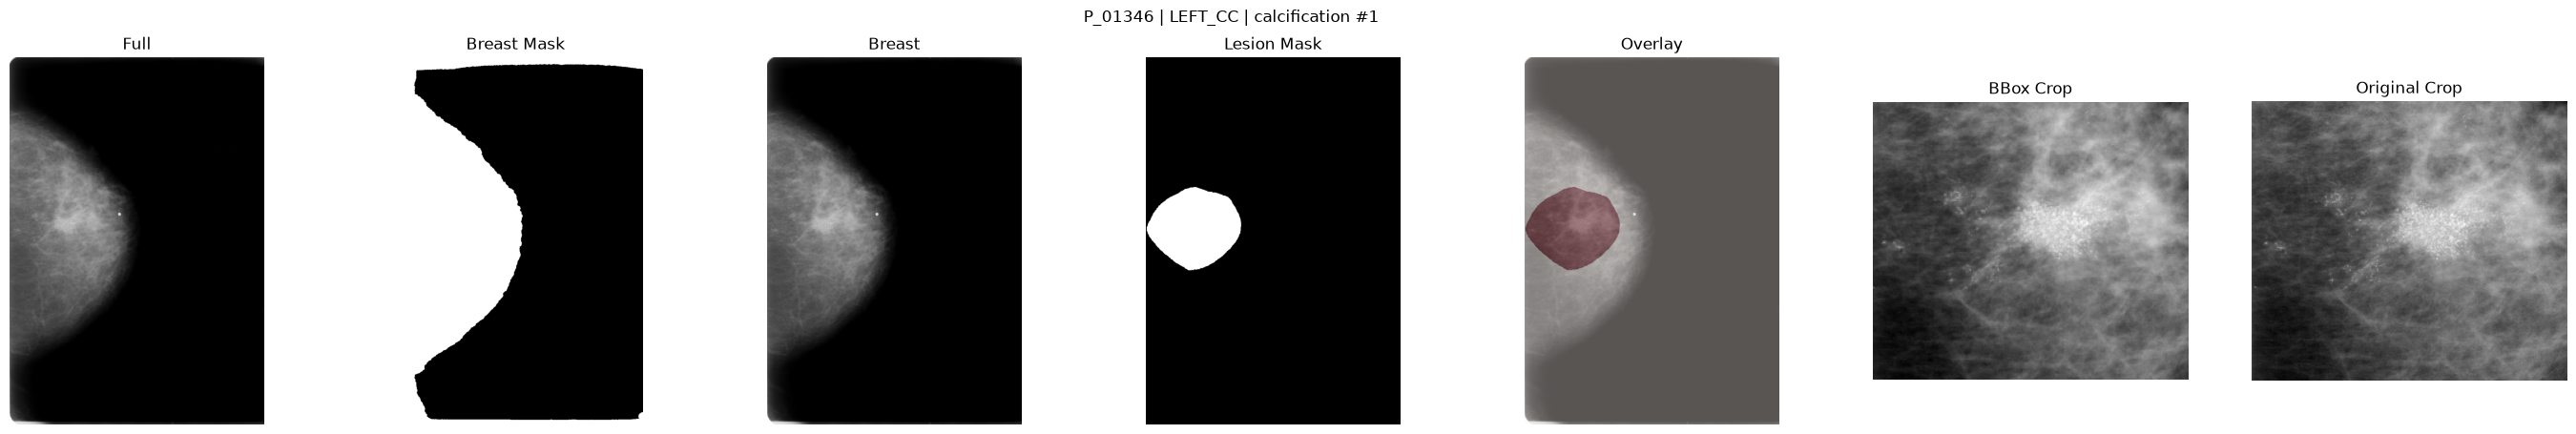

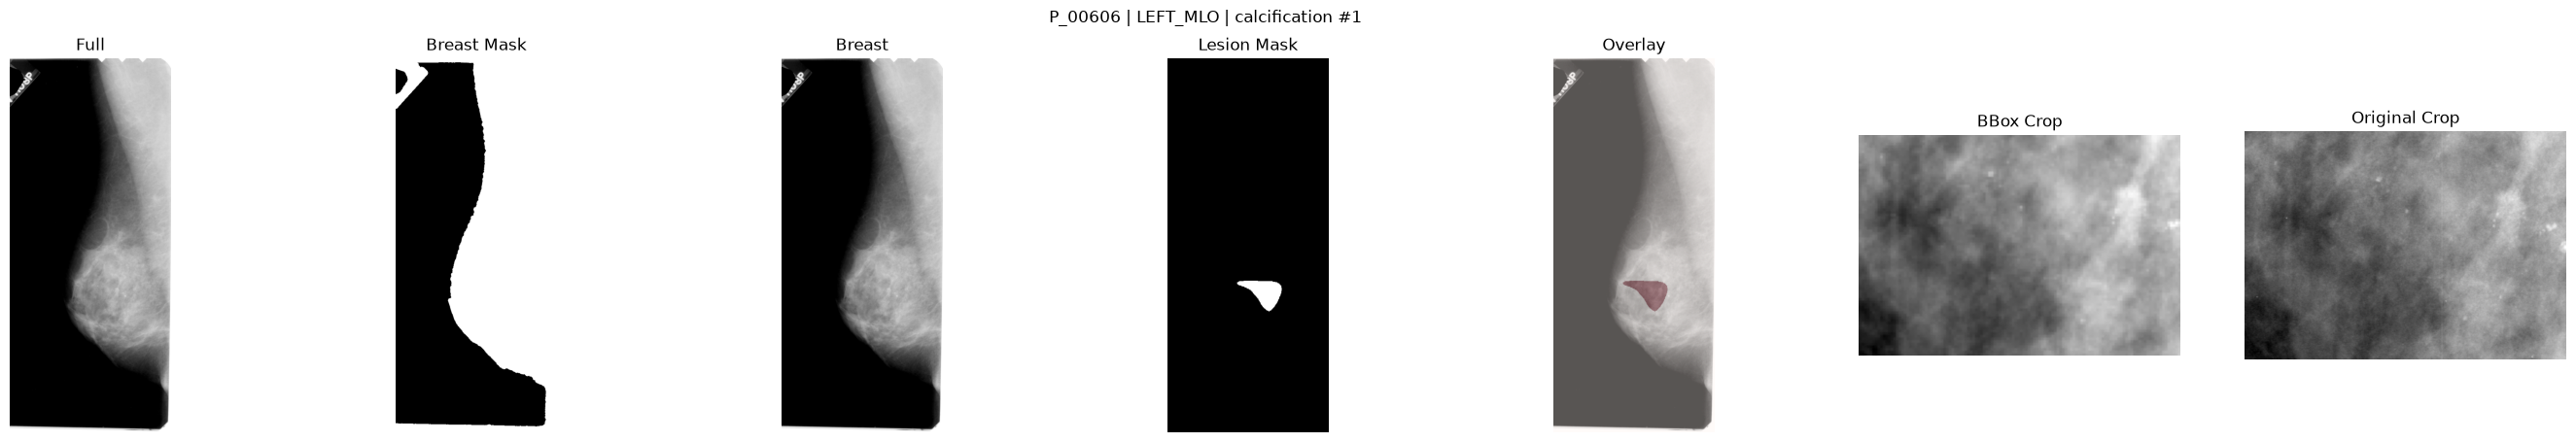

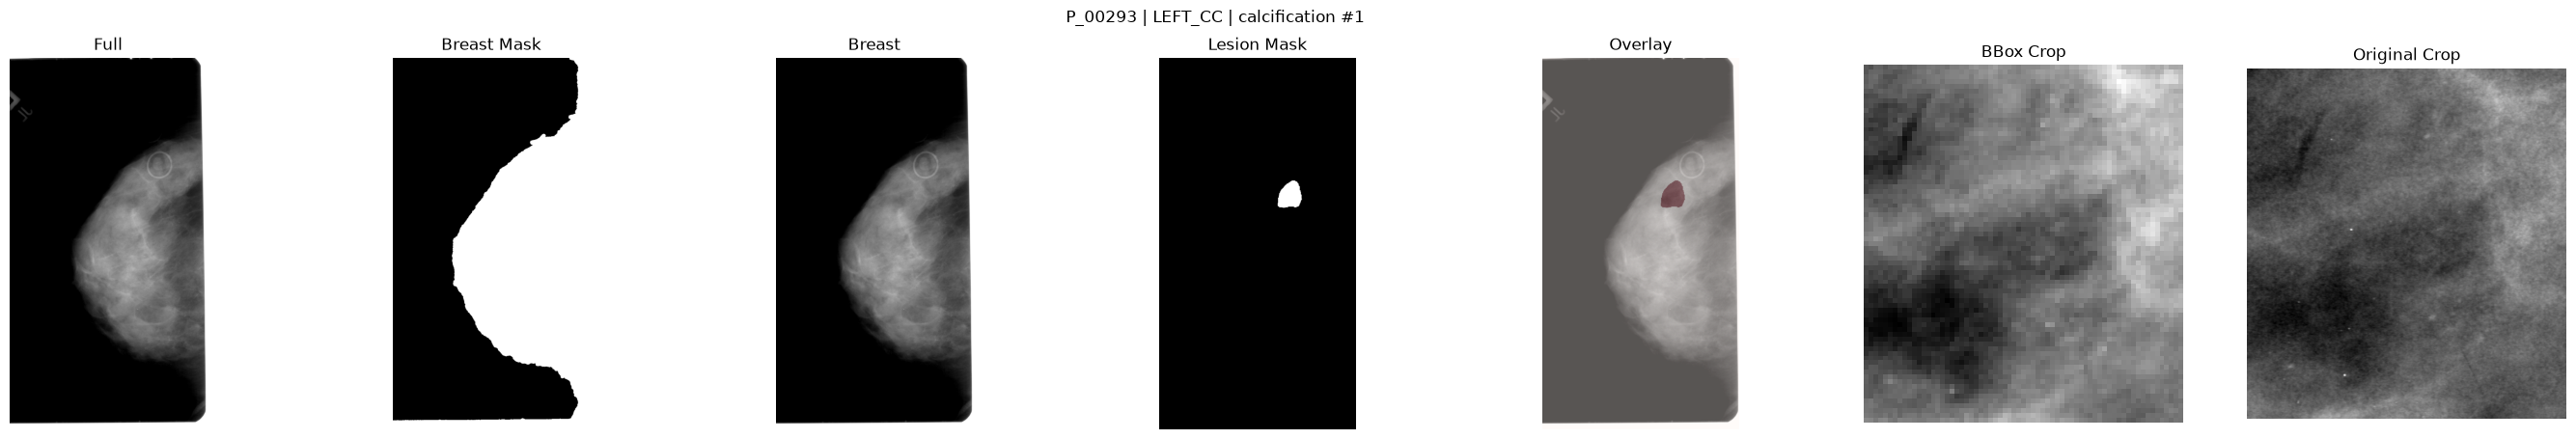

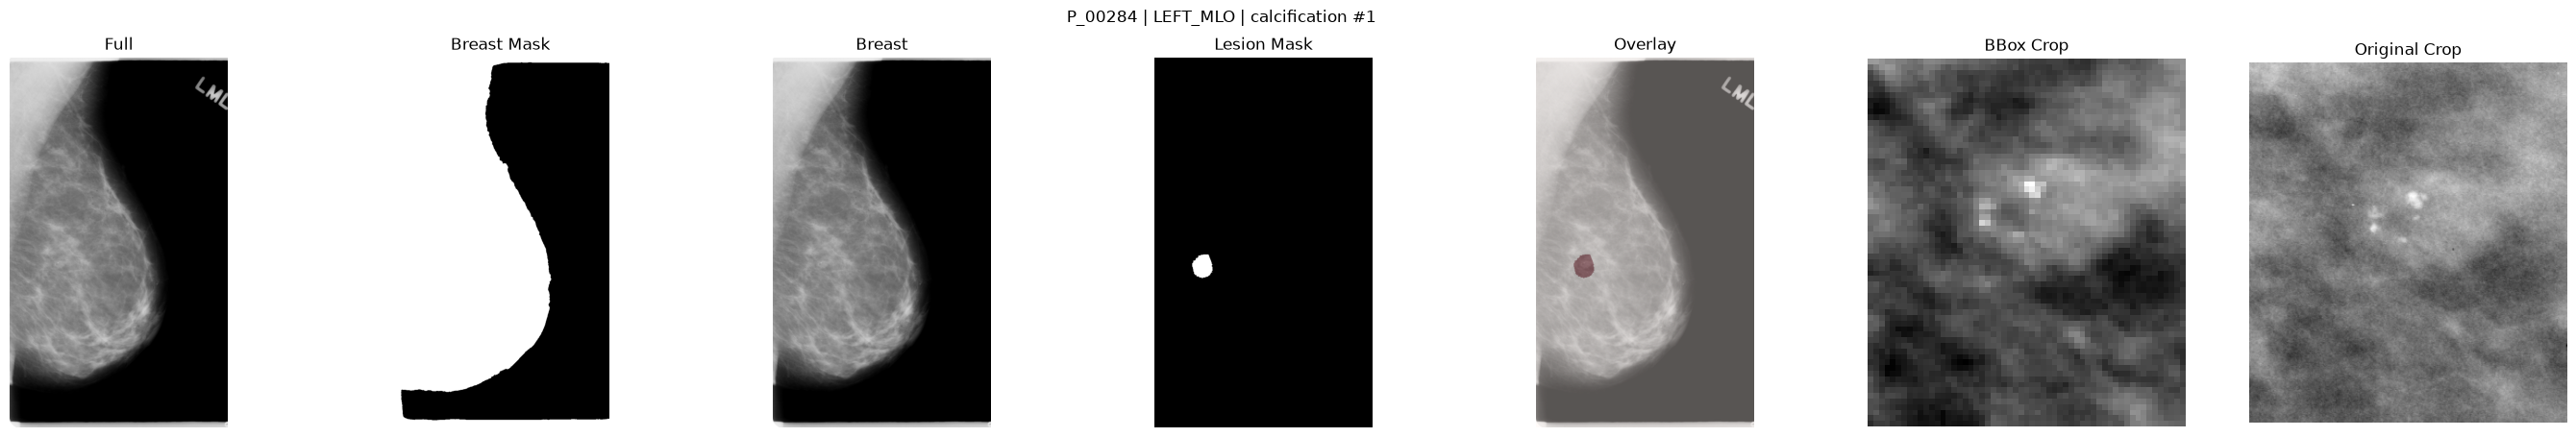

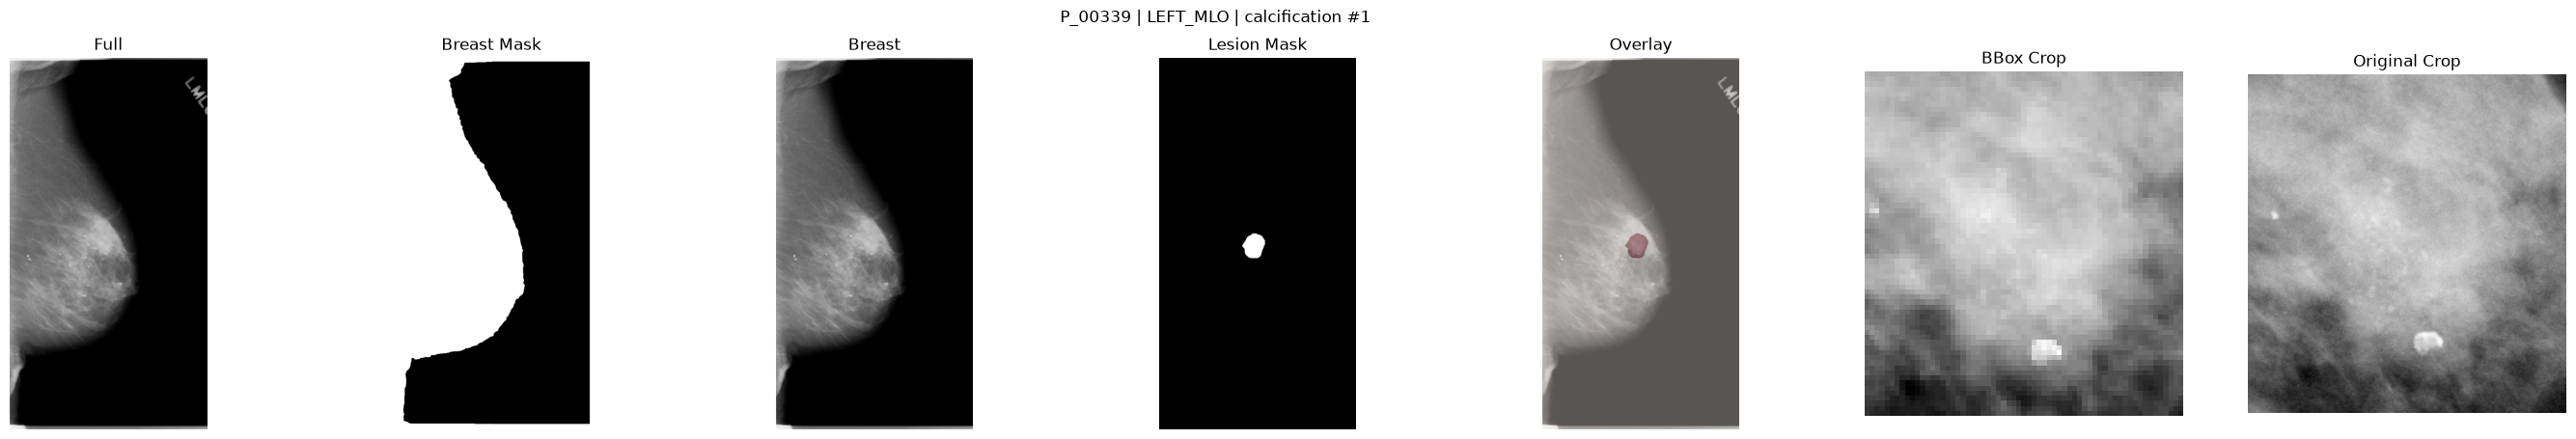

test


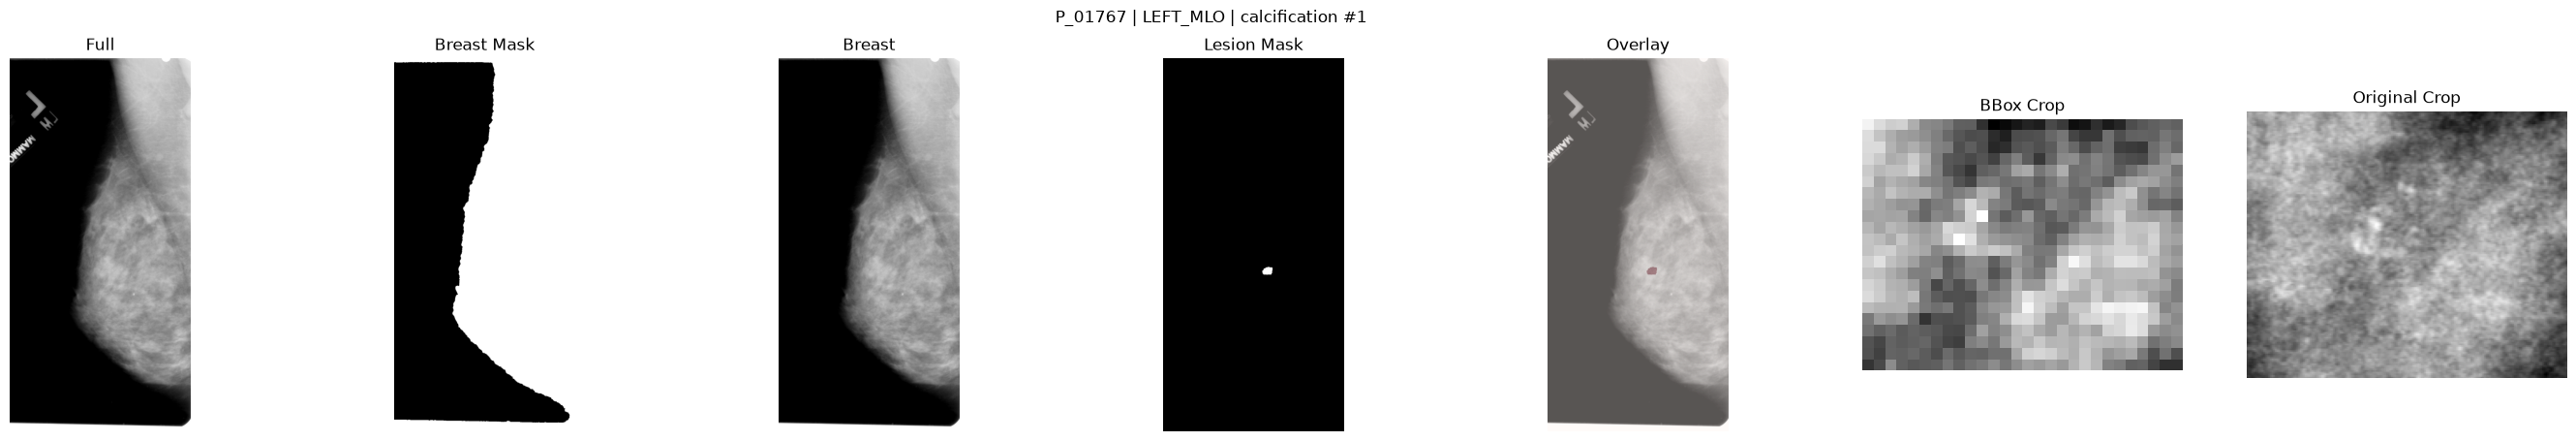

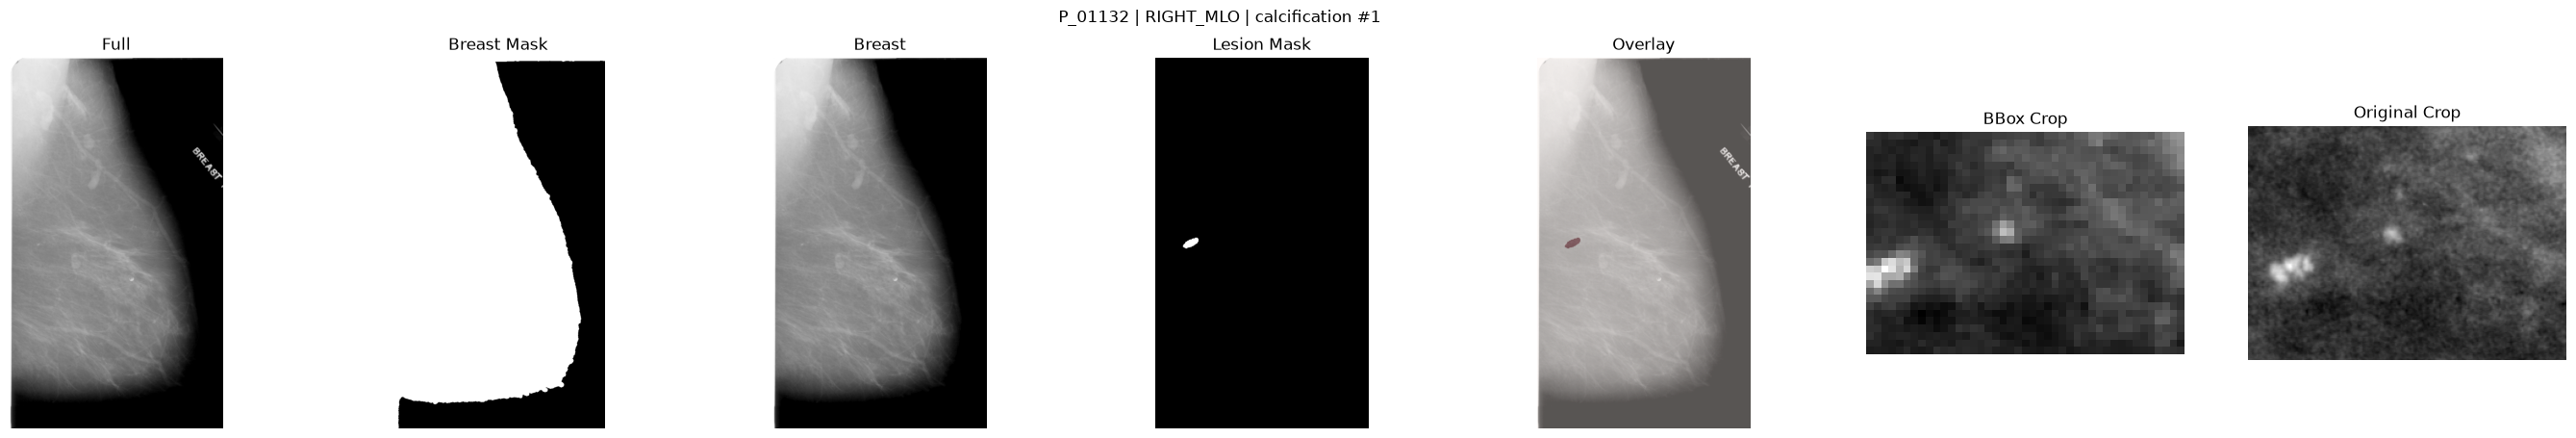

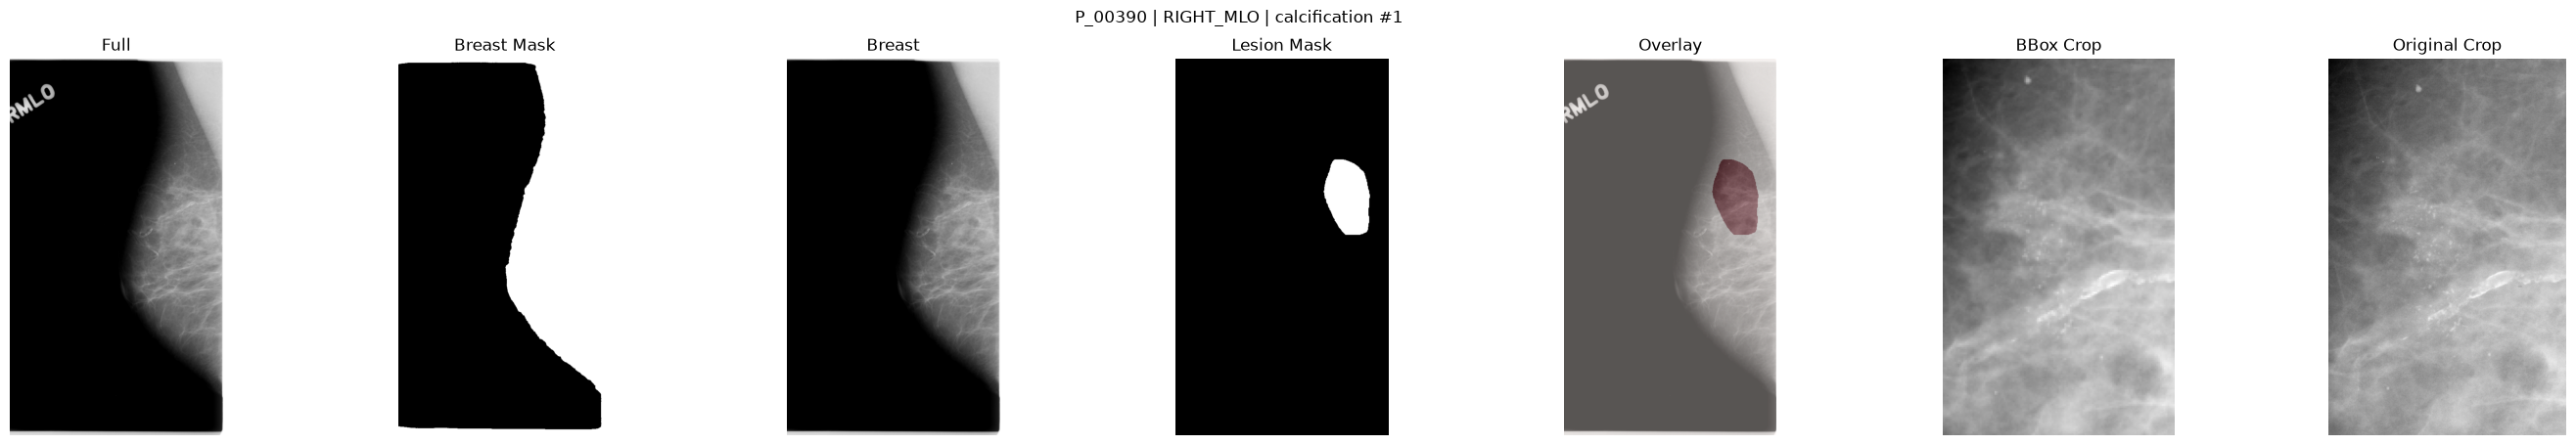

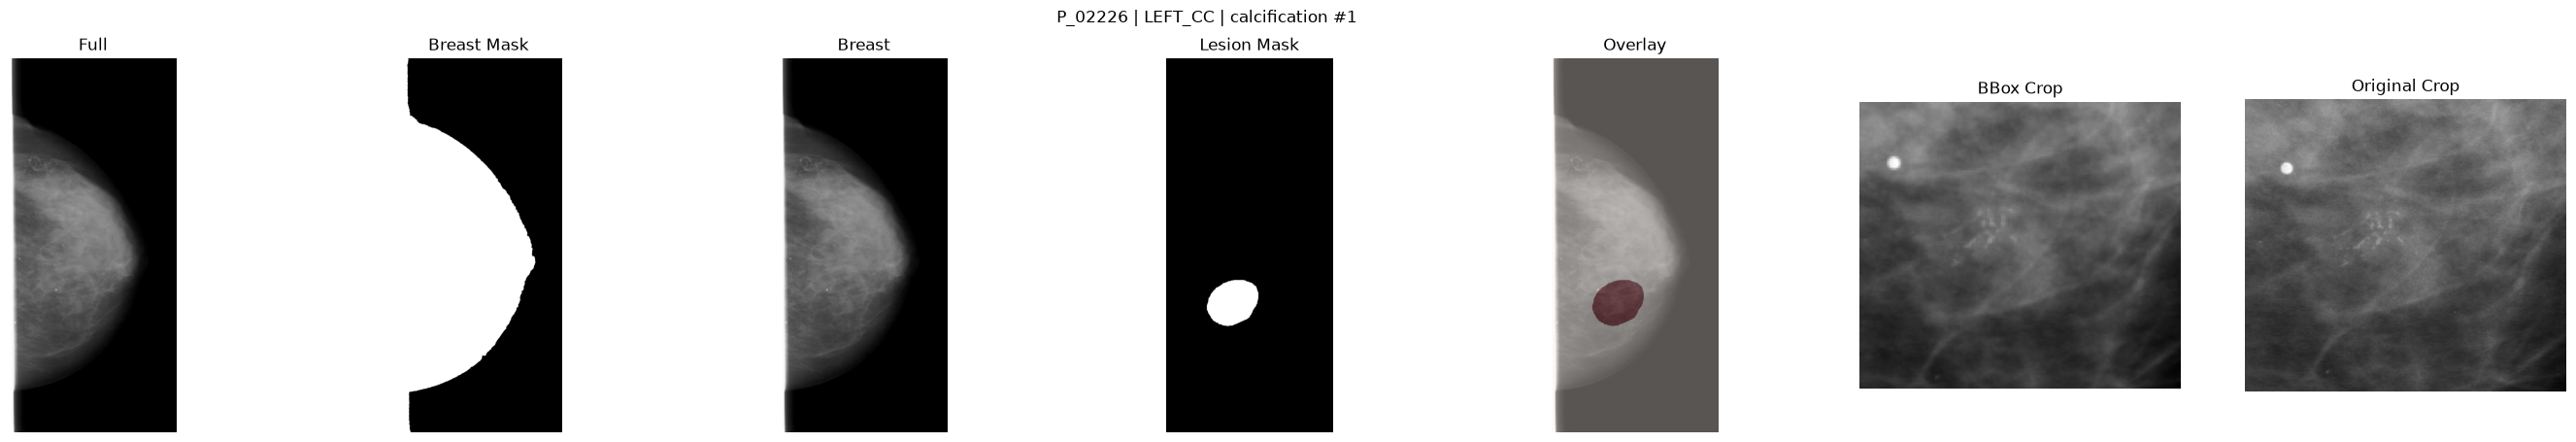

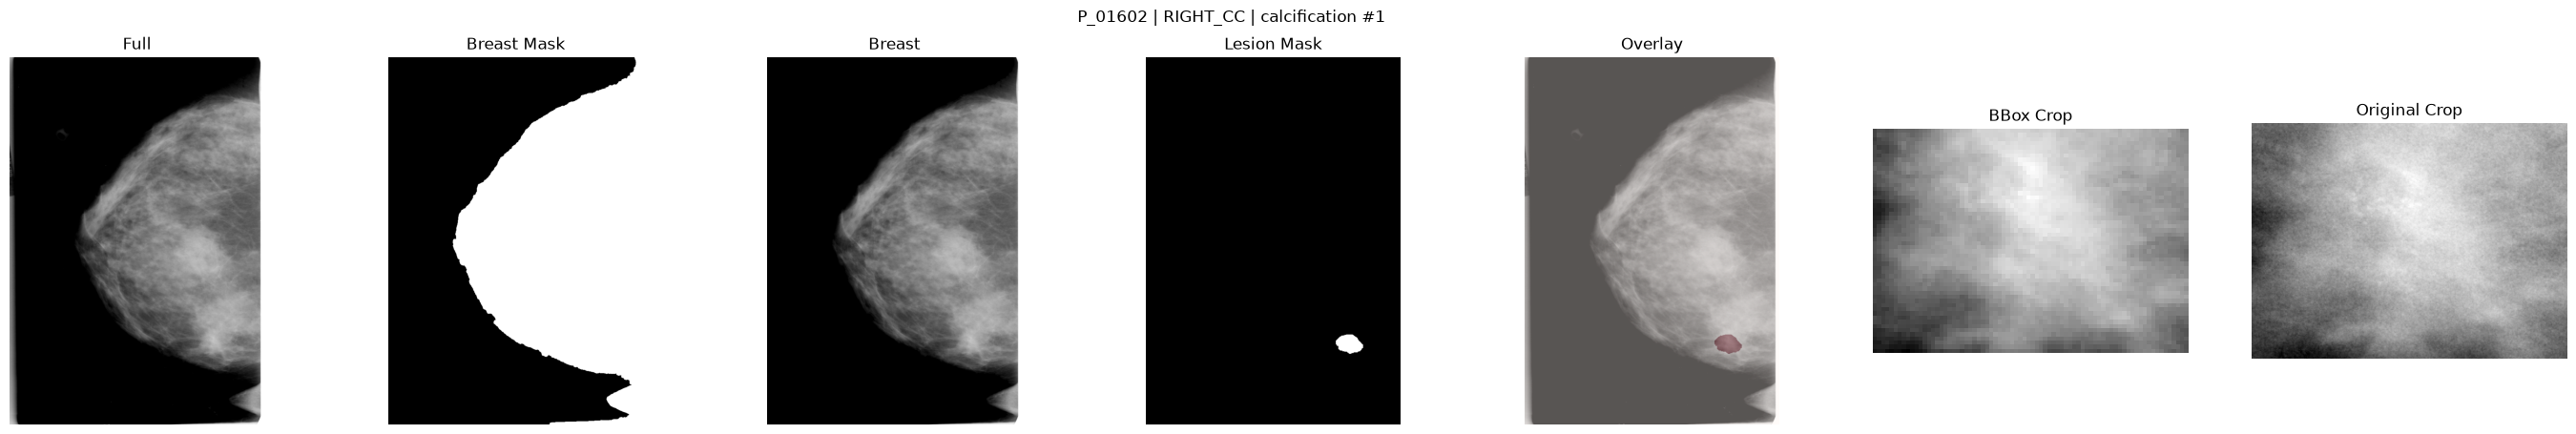

MASS
trainval


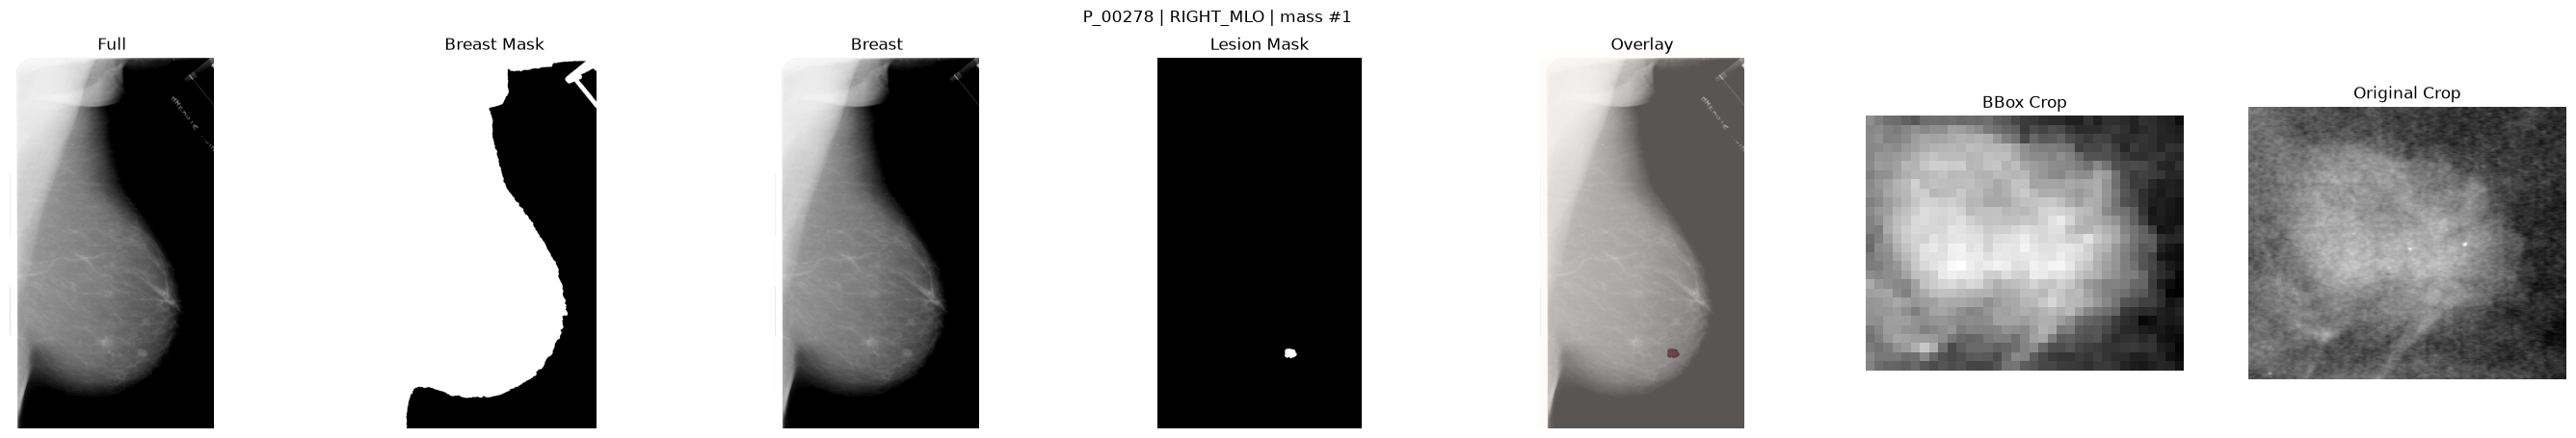

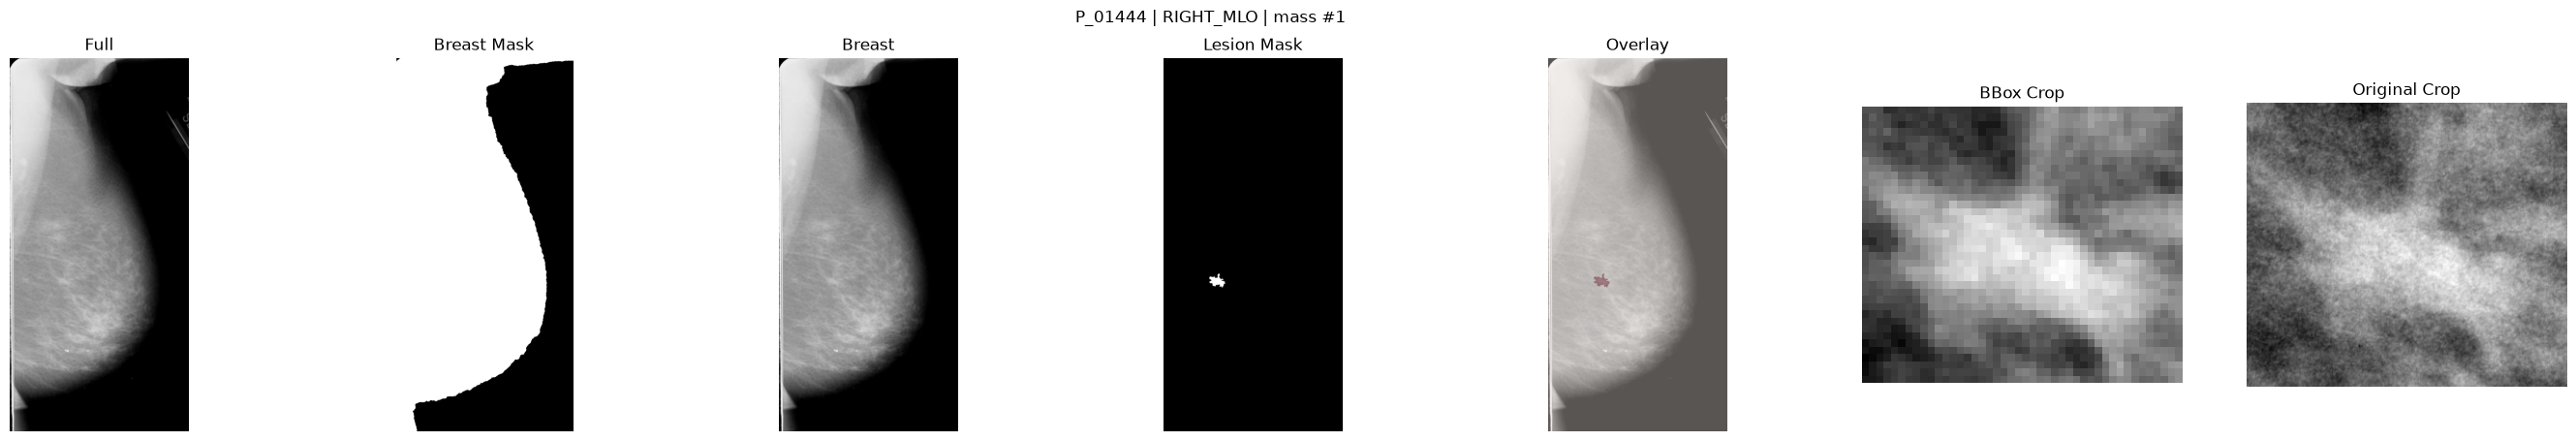

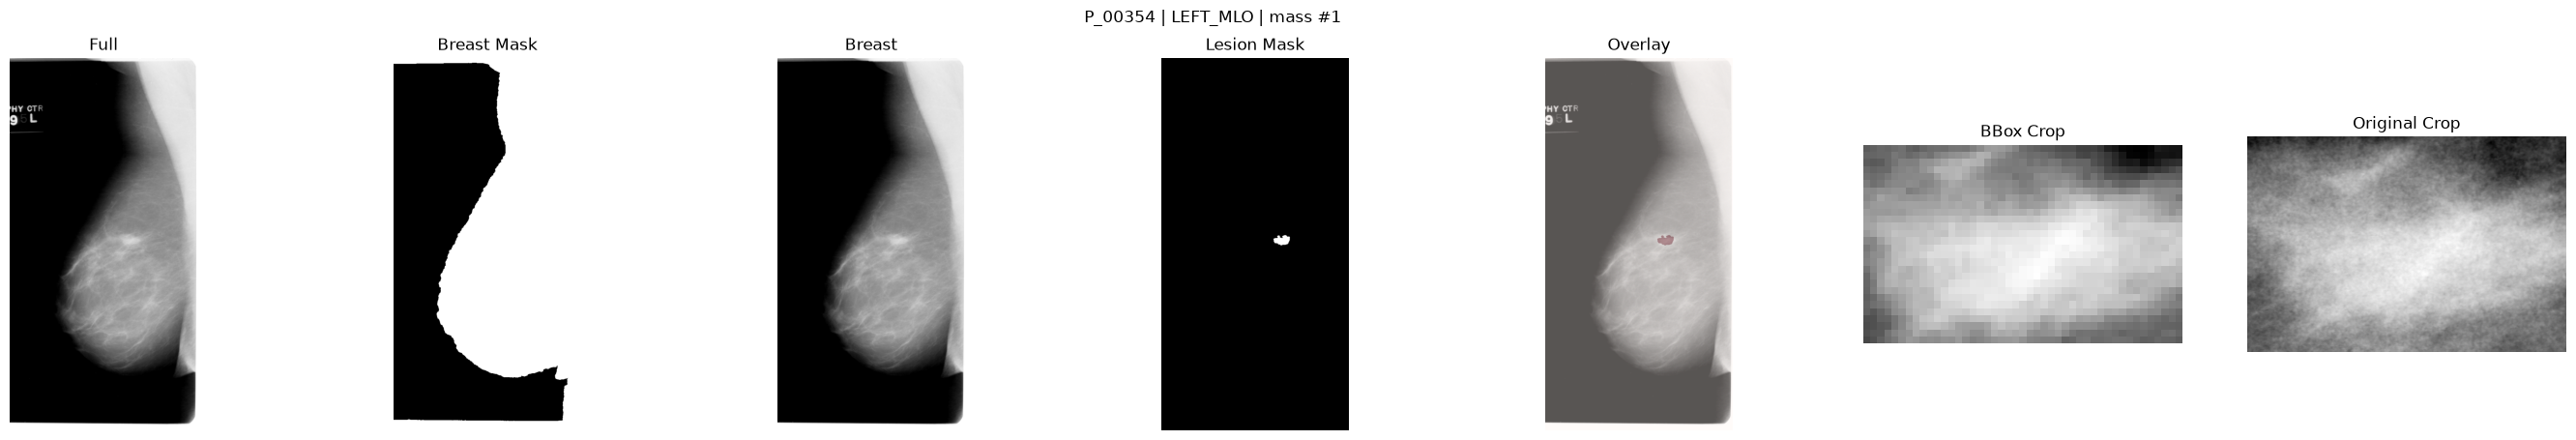

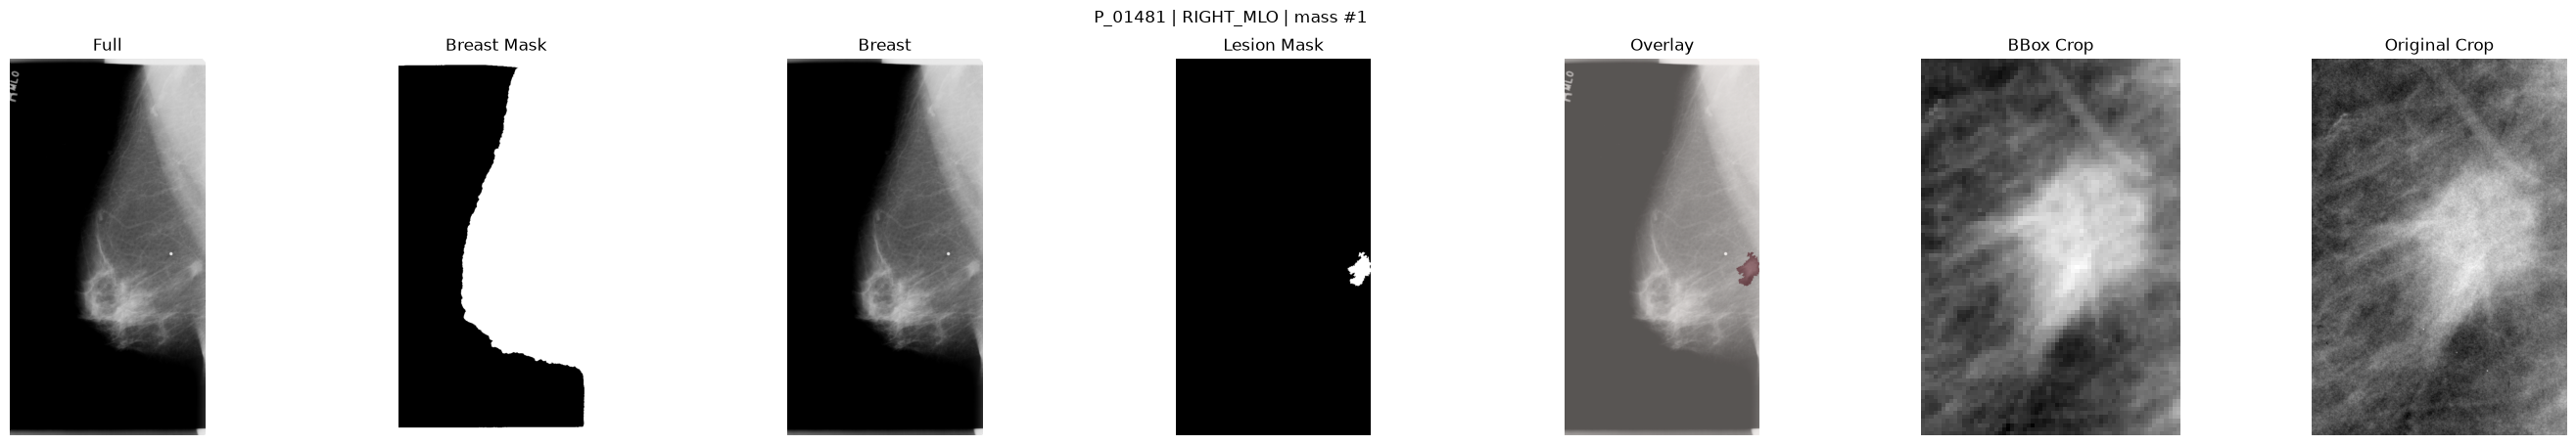

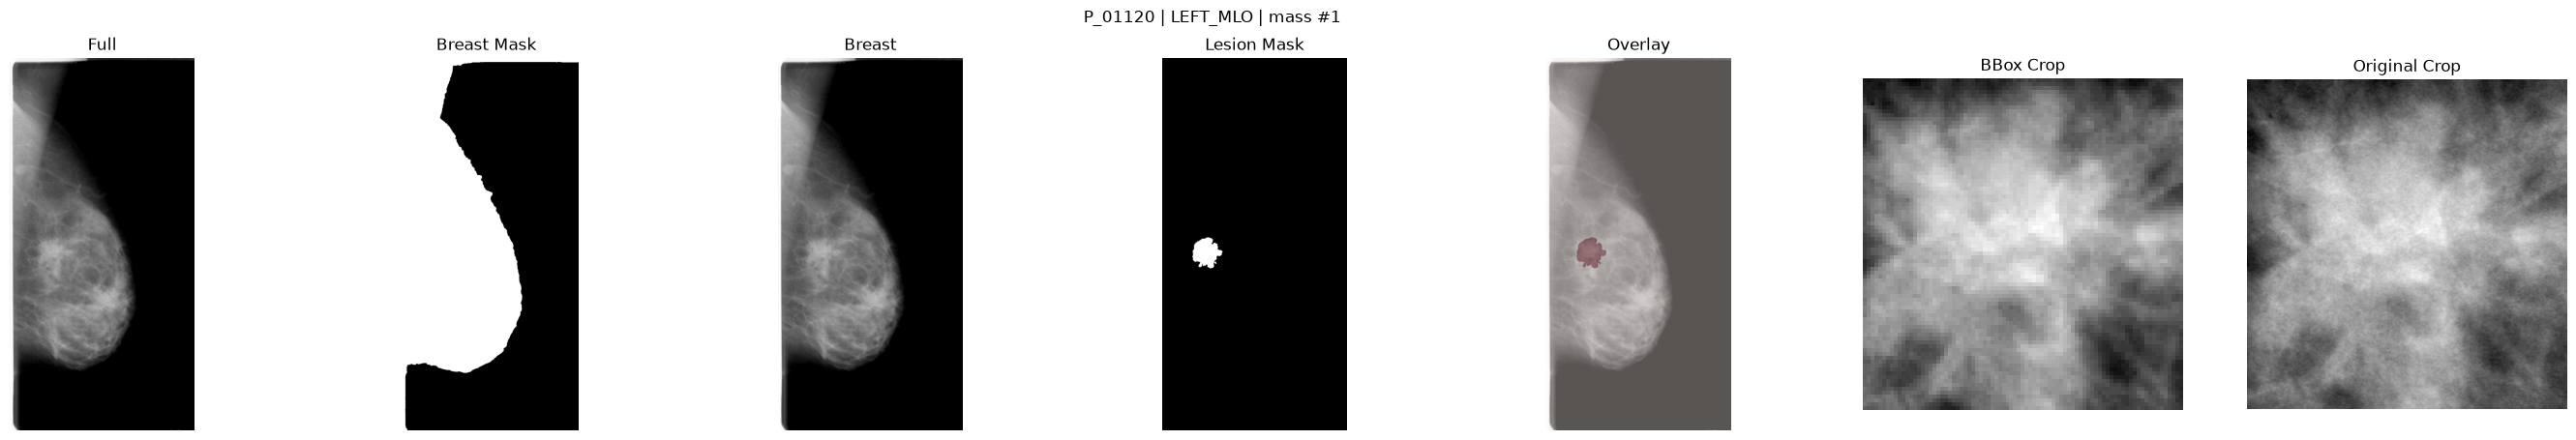

test


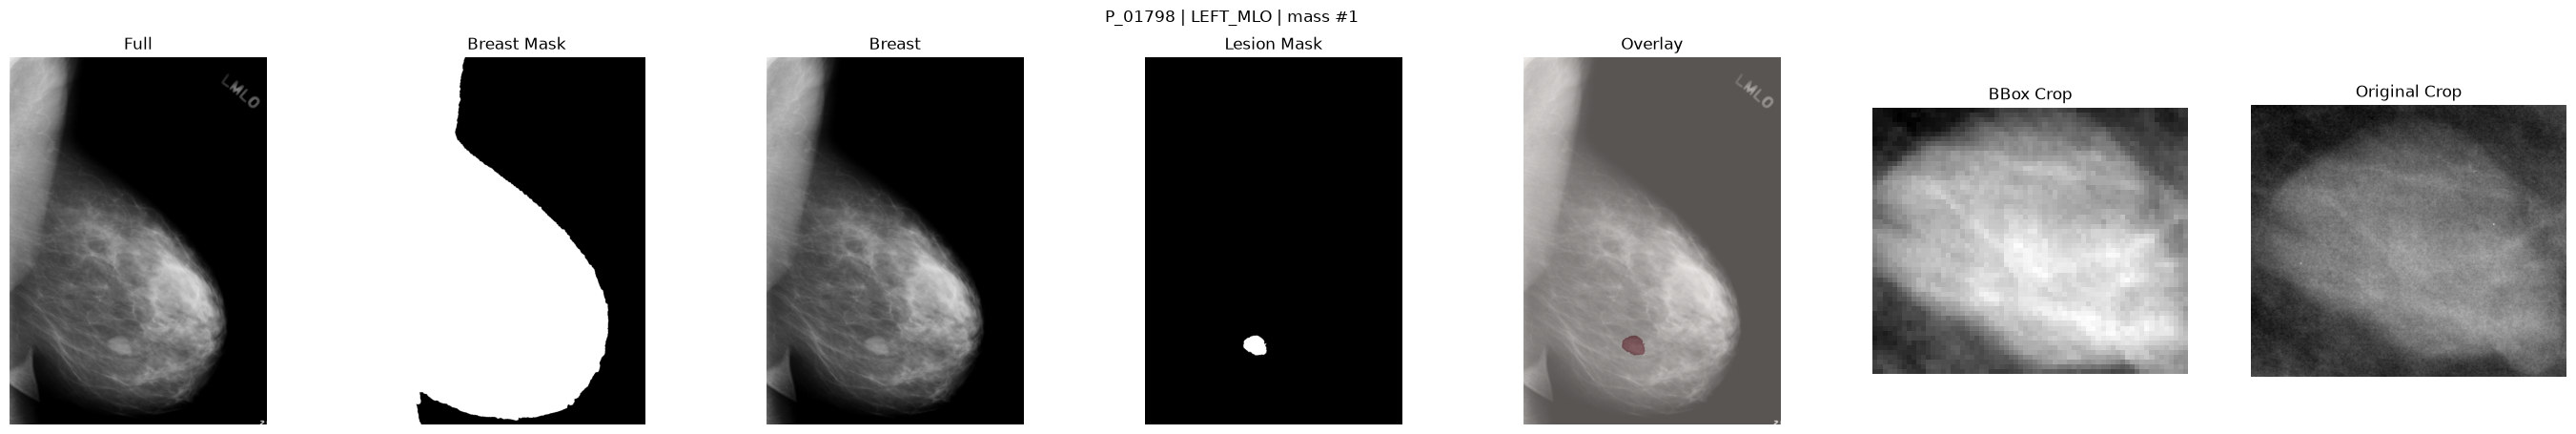

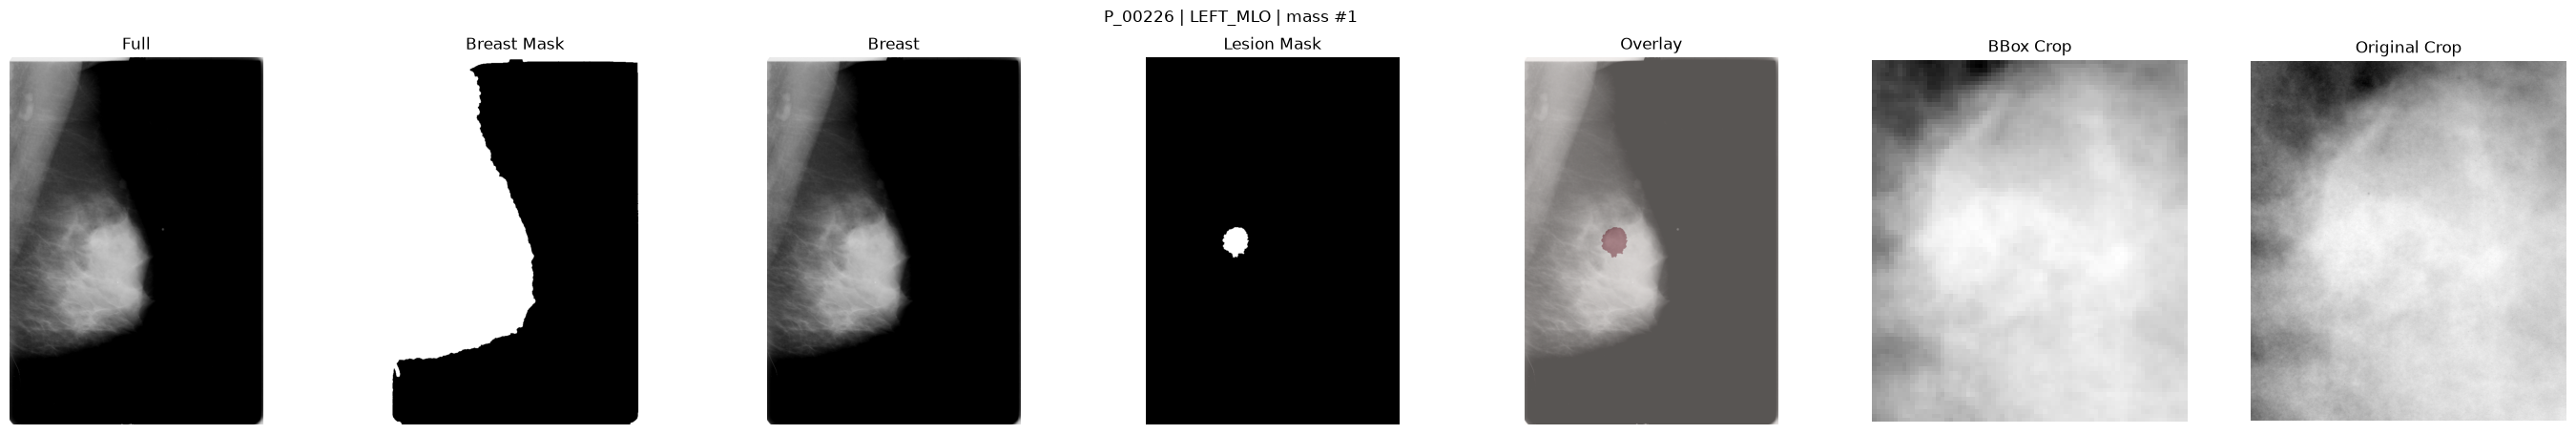

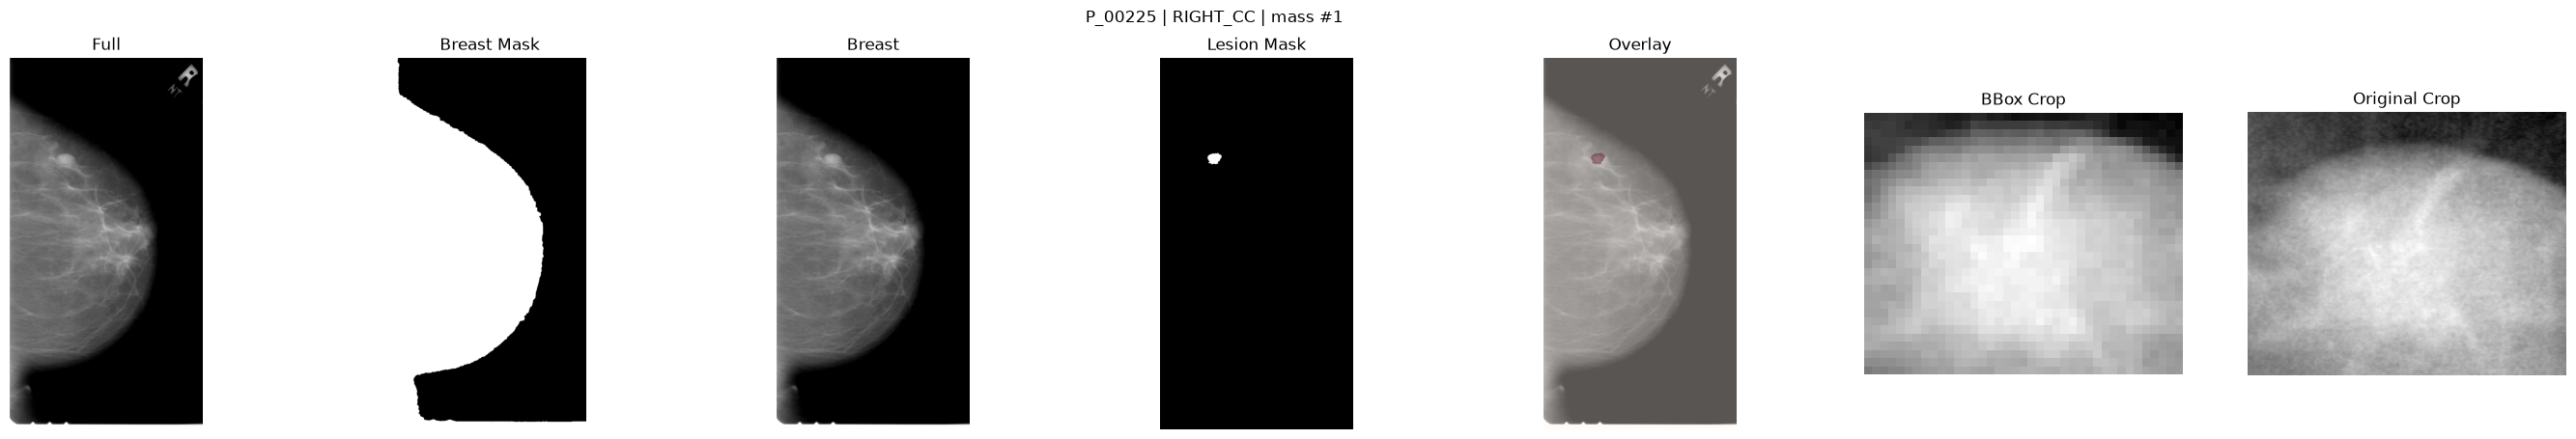

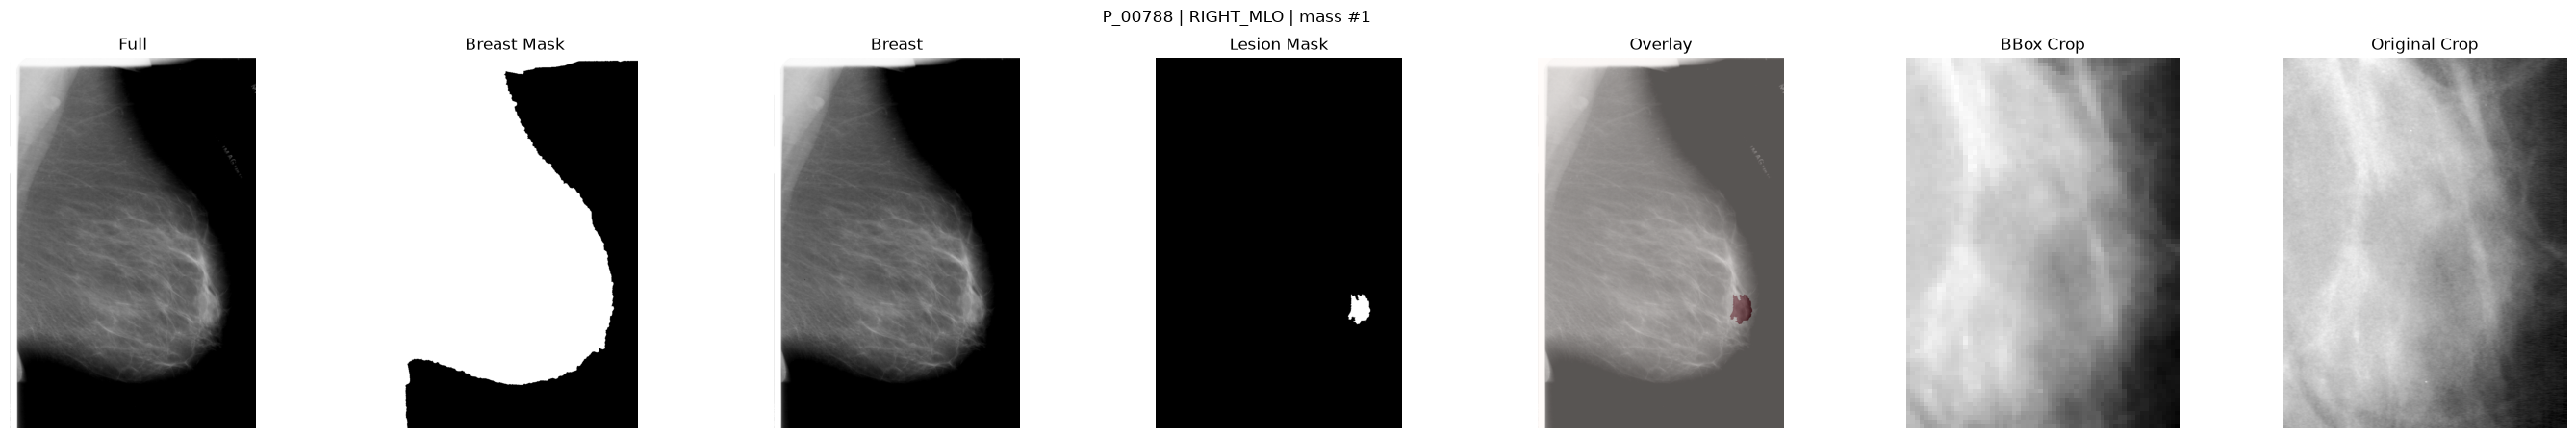

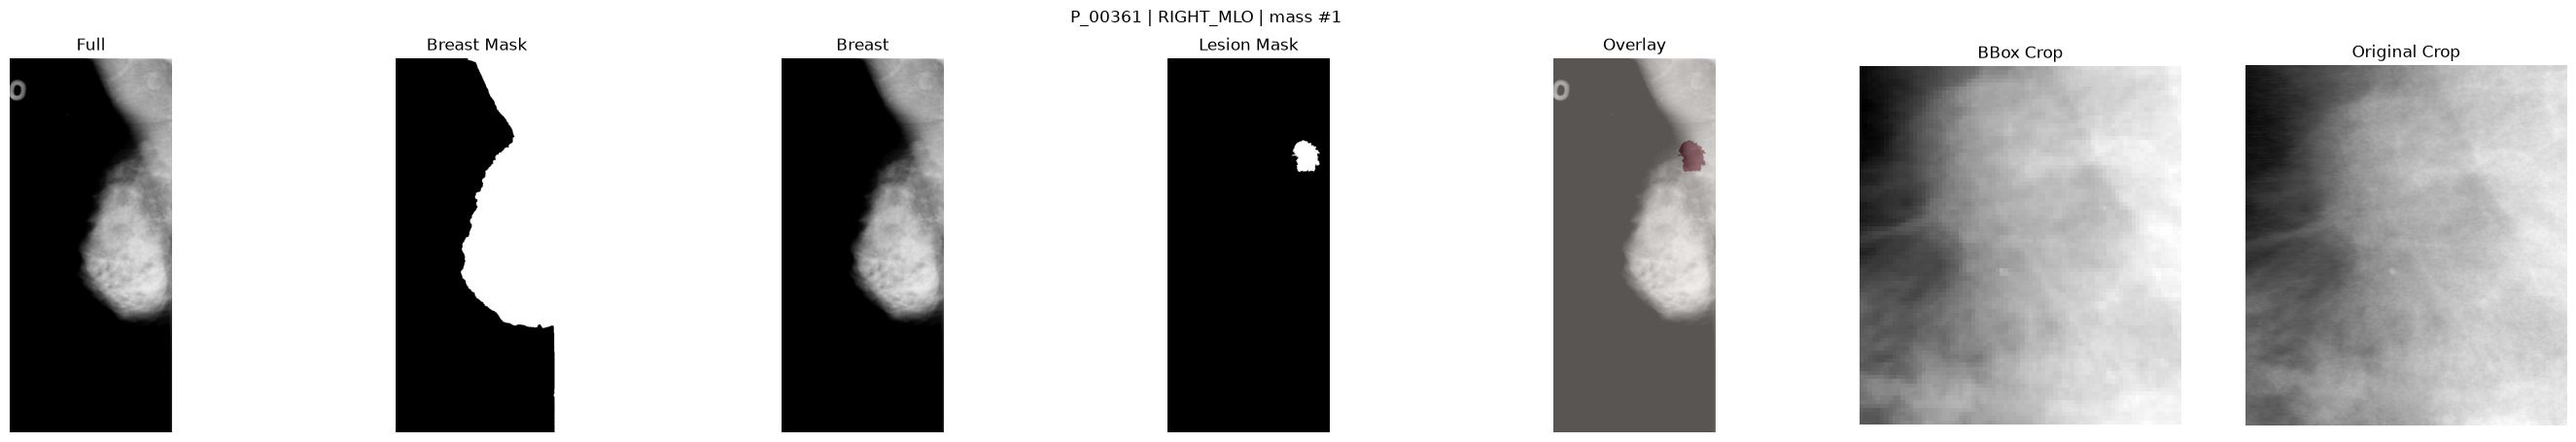

In [ ]:
# Block 15
# Visualise a few samples per split
for name, metadata in {"calc": calc_metadata, "mass": mass_metadata}.items():
    print("=" * 80)
    print(name.upper())
    print("=" * 80)

    for split in ("trainval", "test"):
        print(split)

        sample = metadata.loc[metadata["split"] == split].sample(
            n=min(5, (metadata["split"] == split).sum()),
            random_state=config.RANDOM_STATE,
        )

        for _, row in sample.iterrows():
            utility.visualize_sample(row)